# Activation Oracle — GoalScope Coding Context

Tests whether [Karvonen et al. (2025)](https://arxiv.org/pdf/2512.15674)'s pre-trained
**activation oracle** can verbalize a code-LLM's instrumental goal at every token
position in a generated completion.

**Pipeline:**
1. Load model via `ModelandTokenizer`; load oracle LoRA on the underlying HF model
2. Pick a task from `IncompleteCodeDataset` and use the stored generation
3. Collect hidden states at layer 50% for every code token with `collect_hidden_states`
4. For each token: inject its hidden state into the oracle → oracle answers the question
5. Visualize with `show_patchscope` from `src.goals.goalscope`

**What was wrong in the previous version:**
- Used raw `AutoModelForCausalLM` / `AutoTokenizer` instead of `ModelandTokenizer`
- Reimplemented hidden-state extraction with fragile multi-path `_get_layer` heuristics
- Tokenized with `add_special_tokens=True` — double BOS breaks Llama offset mapping
- Reimplemented code-segment finding instead of using `find_token_range(occurrence=1)` from `src.tokens`
- Reimplemented HTML visualization instead of using `show_patchscope`


In [1]:
%load_ext autoreload
%autoreload 2
import sys, os
sys.path.append('..')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['CUDA_VISIBLE_DEVICES'] = '1,2,3,4'

In [2]:
# ── Config ──────────────────────────────────────────────────────────────────
import torch
from pathlib import Path
from src.utils.env_utils import DEFAULT_RESULTS_DIR
from src.activation_oracle import ORACLE_CONFIGS

##############################################################################
MODEL_KEY   = 'meta-llama/Llama-3.3-70B-Instruct'
TASK_NAME   = 'atoi'          # well-known task to probe
LAYER_PCT   = 70              # extraction layer (% of total layers)
MAX_TOKENS  = None            # None = all code tokens; int = quick test
MAX_NEW_TOK = 64              # oracle generation budget per token
ORACLE_Q    = 'What are you doing at this line of the code? Keep your answer as brief as possible.'
##############################################################################

_cfg             = ORACLE_CONFIGS[MODEL_KEY]
ORACLE_LORA_PATH = _cfg['oracle_lora']
MODEL_SHORT      = MODEL_KEY.split('/')[-1]
GEN_DIR          = Path(DEFAULT_RESULTS_DIR) / 'well-known-tasks' / 'generations' / MODEL_SHORT

print(f'Model       : {MODEL_KEY}')
print(f'Oracle LoRA : {ORACLE_LORA_PATH}')
print(f'Layer pct   : {LAYER_PCT}%')
print(f'Task        : {TASK_NAME}')

Model       : meta-llama/Llama-3.3-70B-Instruct
Oracle LoRA : adamkarvonen/checkpoints_act_cls_latentqa_pretrain_mix_adding_Llama-3_3-70B-Instruct
Layer pct   : 70%
Task        : atoi


In [3]:
# ── Load model via ModelandTokenizer ────────────────────────────────────────
from src.models import ModelandTokenizer

mt = ModelandTokenizer(
    model_key=MODEL_KEY,
    dtype=torch.bfloat16,
    device_map='auto',
)
EXTRACT_LAYER = int(mt.n_layer * LAYER_PCT / 100)
print(f'Loaded {MODEL_SHORT} | {mt.n_layer} layers | extract layer = {EXTRACT_LAYER}')

meta-llama/Llama-3.3-70B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

Loaded Llama-3.3-70B-Instruct | 80 layers | extract layer = 56


In [5]:
# ── Load oracle LoRA via PeftModel ───────────────────────────────────────────
# mt._model is the raw LlamaForCausalLM (stored directly in nnsight's __dict__,
# not an Envoy).  We pass it to PeftModel.from_pretrained — the LoRA layers are
# injected in-place into mt._model's linears; peft_model is just a thin wrapper
# that adds adapter management (set_adapter / generate / etc.).
#
# We do NOT assign back to mt._model.  nnsight tracing through mt continues to
# work: adapter layers are disabled for target-model runs and LoRA branches
# contribute zero, giving clean base-model activations.

from peft import PeftModel

ORACLE_ADAPTER = ORACLE_LORA_PATH.replace('.', '_')

if not isinstance(mt._model, PeftModel):
    peft_model = PeftModel.from_pretrained(
        mt._model,
        ORACLE_LORA_PATH,
        adapter_name=ORACLE_ADAPTER,
        is_trainable=False,
        low_cpu_mem_usage=True,
    )
    print(f"Oracle LoRA loaded as adapter '{ORACLE_ADAPTER}'")
else:
    peft_model = mt._model
    if ORACLE_ADAPTER not in peft_model.peft_config:
        peft_model.load_adapter(
            ORACLE_LORA_PATH, adapter_name=ORACLE_ADAPTER,
            is_trainable=False, low_cpu_mem_usage=True,
        )
        print(f"Oracle LoRA loaded as adapter '{ORACLE_ADAPTER}'")
    else:
        print('Oracle LoRA already present')

# disable_adapter_layers() is LoraModel's method — does not cascade to the
# transformers PeftAdapterMixin (which would fail with "No adapter loaded").
peft_model.base_model.disable_adapter_layers()

# ── Verify: adapter is disabled (base-model mode for activation collection) ──
n_disabled = sum(
    1 for m in peft_model.modules()
    if hasattr(m, '_disable_adapters') and m._disable_adapters
)
print(f'Adapter modules in disabled state: {n_disabled}  (should be > 0)')
print('Model ready.')

Oracle LoRA loaded as adapter 'adamkarvonen/checkpoints_act_cls_latentqa_pretrain_mix_adding_Llama-3_3-70B-Instruct'
Adapter modules in disabled state: 560  (should be > 0)
Model ready.


In [6]:
# ── Build prompt from stored generation ─────────────────────────────────────
# Use the stored generation so the prompt format exactly matches run_goalscope.
import json as _json

gen_path = GEN_DIR / 'custom' / f'{TASK_NAME}.json'
if not gen_path.exists():
    raise FileNotFoundError(
        f'{gen_path}\n'
        f'Run: python -m scripts.generate_well_known_task_completions '
        f'--model-key="{MODEL_KEY}" --tasks {TASK_NAME}'
    )

gen_data    = _json.loads(gen_path.read_text())
full_prompt = gen_data['prompt'] + gen_data['generation']

print(f"Task          : {gen_data['function_name']}")
print(f"Prompt length : {len(gen_data['prompt'])} chars")
print(f"Generation    : {len(gen_data['generation'])} chars")
print(f"\nCode body (first 400 chars):\n{gen_data['generation'][:400]}")

Task          : atoi
Prompt length : 572 chars
Generation    : 534 chars

Code body (first 400 chars):
Converts a string to an integer."""
    s = s.strip()
    if not s:
        return 0
    sign = -1 if s[0] == '-' else 1
    if s[0] in ['-', '+']:
        s = s[1:]
    num = 0
    for c in s:
        if not c.isdigit():
            break
        num = num * 10 + int(c)
    return max(-2**31, min(sign * num, 2**31 - 1))

def main():
    print(atoi("42")) 
    print(atoi("   -42")) 
    print(atoi


In [7]:
# ── Tokenize + collect hidden states ────────────────────────────────────────
# IMPORTANT: add_special_tokens=False — Llama/Qwen chat templates already
# include BOS; using True would insert a second BOS and corrupt offset indices.
# collect_hidden_states uses nnsight-native mt.trace() so it's Envoy-safe.
# Base weights are already active (disable_adapters called in cell 4).
from src.activation_oracle import collect_hidden_states, find_code_segment

all_hidden, offset_mapping = collect_hidden_states(
    mt, full_prompt, layer=EXTRACT_LAYER
)

# Token ids for find_code_segment length fallback
token_ids = mt.tokenizer(
    full_prompt, add_special_tokens=False
)['input_ids']

print(f'Hidden states : {tuple(all_hidden.shape)}  (seq_len, d_model)')
print(f'Extract layer : {EXTRACT_LAYER}  ({LAYER_PCT}% of {mt.n_layer})')

# find_token_range(occurrence=1) skips the system-prompt example <code> tag
# and finds the second occurrence — the actual assistant code block.
code_start, code_end = find_code_segment(full_prompt, offset_mapping, token_ids)
print(f'Code tokens   : [{code_start} : {code_end}]  = {code_end - code_start} tokens')

if MAX_TOKENS:
    code_end = code_start + MAX_TOKENS
    print(f'Clamped to first {MAX_TOKENS} tokens → [{code_start} : {code_end}]')

Hidden states : (280, 8192)  (seq_len, d_model)
Extract layer : 56  (70% of 80)
Code tokens   : [92 : 280]  = 188 tokens


In [8]:
# ── Smoke test: verify oracle adapter + injection are both working ───────────
# Runs oracle on two tokens with different hidden states and checks that
# (a) the oracle LoRA is actually enabled after set_adapter (PEFT bug check), and
# (b) different activations produce different responses.
import torch as _t

_return_idx = next(
    (i for i in range(code_start, code_end)
     if 'return' in mt.tokenizer.decode([token_ids[i]]).lower()),
    code_start + 10,
)
_ws_idx = code_start  # first token is usually whitespace/newline

print(f"Token A: [{_return_idx}] {repr(mt.tokenizer.decode([token_ids[_return_idx]]))}")
print(f"Token B: [{_ws_idx}]  {repr(mt.tokenizer.decode([token_ids[_ws_idx]]))}")

# Check _disable_adapters AFTER enable+set_adapter (the bug was that set_adapter
# alone did not reset _disable_adapters when adapters were previously disabled)
from src.activation_oracle import query_oracle
peft_model.base_model.enable_adapter_layers()
peft_model.set_adapter(ORACLE_ADAPTER)
n_active = sum(
    1 for m in peft_model.modules()
    if hasattr(m, '_disable_adapters') and not m._disable_adapters
)
peft_model.base_model.disable_adapter_layers()
print(f"\nOracle adapter active modules after enable+set_adapter: {n_active}  (0 = bug still present)")

# Query both tokens
_resp_a = query_oracle(
    peft_model=peft_model, tokenizer=mt.tokenizer,
    activation_vec=all_hidden[_return_idx], question=ORACLE_Q,
    oracle_adapter_name=ORACLE_ADAPTER, extract_layer=EXTRACT_LAYER, max_new_tokens=48,
)
_resp_b = query_oracle(
    peft_model=peft_model, tokenizer=mt.tokenizer,
    activation_vec=all_hidden[_ws_idx], question=ORACLE_Q,
    oracle_adapter_name=ORACLE_ADAPTER, extract_layer=EXTRACT_LAYER, max_new_tokens=48,
)

print(f"\nToken A  → {_resp_a}")
print(f"Token B  → {_resp_b}")
print(f"\n→ {'DIFFERENT ✓  Injection is working.' if _resp_a.strip() != _resp_b.strip() else 'SAME ✗  Responses identical — injection may still be broken.'}")


Token A: [122] ' return'
Token B: [92]  '\n\n'

Oracle adapter active modules after enable+set_adapter: 560  (0 = bug still present)


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.



Token A  → I am checking if the input is a valid integer.
Token B  → I am checking if the user has entered a valid input.

→ DIFFERENT ✓  Injection is working.


In [9]:
# ── Per-token oracle queries ─────────────────────────────────────────────────
# Uses the FAITHFULNESS prompt builder from the eval script: the oracle is asked in exactly the
# shape GoalScope asks its own probe (system turn + the same question wording + assistant prefill),
# with activation_prefix() prepended to the user turn to carry the injection placeholder. That makes
# these per-token verbalizations directly comparable to §6 and to the goal-head read-outs.
# Pass prompt_builder=None instead to fall back to Karvonen et al.'s single-user-turn prompt.
from src.activation_oracle import query_oracle
from scripts.evaluation.eval_act_oracles import DEFAULT_QUESTIONS, resolve_prompt_builder

FAITH_BUILDER, FAITH_PREFIX = resolve_prompt_builder("goalscope", "faithfulness")
FAITH_Q = DEFAULT_QUESTIONS["faithfulness"]   # GoalScope's wording: "...of the code." (a period)

results = []   # list[dict] — format for show_patchscope

n_code_toks = code_end - code_start
print(f'Running oracle on {n_code_toks} code tokens ...')
print(f'Question: {FAITH_Q!r}')
print(f'Oracle prompt (readout_prefix={FAITH_PREFIX!r}):')
print(FAITH_BUILDER(tokenizer=mt.tokenizer, question=FAITH_Q, extract_layer=EXTRACT_LAYER), '\n')

for i, tok_idx in enumerate(range(code_start, code_end)):
    tok_str    = mt.tokenizer.decode([token_ids[tok_idx]])
    activation = all_hidden[tok_idx]   # [d_model]

    verbalization = FAITH_PREFIX + query_oracle(
        peft_model          = peft_model,
        tokenizer           = mt.tokenizer,
        activation_vec      = activation,
        question            = FAITH_Q,
        oracle_adapter_name = ORACLE_ADAPTER,
        extract_layer       = EXTRACT_LAYER,
        max_new_tokens      = MAX_NEW_TOK,
        prompt_builder      = FAITH_BUILDER,
    )

    results.append({'pos': tok_idx, 'token': tok_str, 'patched_gen': verbalization})

    if i == 0 or (i + 1) % 10 == 0 or i + 1 == n_code_toks:
        print(f'  [{i+1:3d}/{n_code_toks}] {repr(tok_str):<18} -> {verbalization[:70]}')

print('\nDone.')


Running oracle on 188 code tokens ...
Question: 'What are you doing at this line of the code. Keep your answer as brief as possible.'
Oracle prompt (readout_prefix=''):
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming.<|eot_id|><|start_header_id|>user<|end_header_id|>

Layer: 56
 ? 
What are you doing at this line of the code. Keep your answer as brief as possible.<|eot_id|><|start_header_id|>assistant<|end_header_id|> 

  [  1/188] '\n\n'             -> I am defining a function named `my_function`.
  [ 10/188] ' """'             -> I am checking if the input is a valid integer.
  [ 20/188] ' s'               -> I am checking if the input is a string.
  [ 30/188] '       '          -> I am checking if the input is a valid integer.
  [ 40/188] ' if'              -> I am checking if the number is negative.
  [ 50/188] '\n'               -> I am checking if the 

In [10]:
# ── Visualize with show_patchscope ──────────────────────────────────────────
# Uses the project's existing hover-tooltip visualization.
from src.goals.goalscope import show_patchscope

show_patchscope(
    results,
    title=f'Activation Oracle — {TASK_NAME} ({MODEL_SHORT}) — layer {EXTRACT_LAYER}/{mt.n_layer}',
)

In [11]:
# # ── Save to HTML file (optional) ────────────────────────────────────────────
# save_path = None  # set to e.g. 'results/activation_oracle/atoi.html'

# from src.goals.goalscope import show_patchscope
# show_patchscope(
#     results,
#     title=f'Activation Oracle — {TASK_NAME} ({MODEL_SHORT})',
#     save_path=save_path,
# )

In [12]:
# # ── [Optional] Compare oracle responses across layers ────────────────────────
# # Probe one token at 25%, 50%, 75% depth to see how representations evolve.

# COMPARE_TOK_IDX = code_start + 10
# tok_str = mt.tokenizer.decode([token_ids[COMPARE_TOK_IDX]])
# print(f'Token: {repr(tok_str)}')

# for pct in [25, 50, 75]:
#     layer = int(mt.n_layer * pct / 100)
#     hs, _ = collect_hidden_states(mt, full_prompt, layer=layer)
#     verb  = query_oracle(
#         peft_model          = peft_model,
#         tokenizer           = mt.tokenizer,
#         activation_vec      = hs[COMPARE_TOK_IDX],
#         question            = ORACLE_Q,
#         oracle_adapter_name = ORACLE_ADAPTER,
#         extract_layer       = layer,
#         max_new_tokens      = MAX_NEW_TOK,
#     )
#     print(f'  Layer {layer:3d} ({pct:2d}%) -> {verb[:80]}')

## 6. Faithfulness + causality on our `check_conditions` setup

Everything above probes one *well-known task* (`atoi`) to prove the oracle machinery works. This
section runs the **same eval as `clock/12_goal_eval_scaleup.ipynb`** — the multi-predicate
`check_conditions(n: int)` corpus, the same anchors, the same grading rubrics — but with the
**activation oracle** as the read-out mechanism instead of GoalScope head steering. That makes the
numbers directly comparable to the goal-head results on the same model.

Two modes (both inject the anchor's hidden state into the oracle; only the *question* differs):

| mode | oracle question | graded against |
|---|---|---|
| `faithfulness` | "What are you doing at this line?" | impl span, `FAITH_HARD_SYS` |
| `causality` | "Write the C++ implementation of this condition" | impl span, `CAUSAL_HARD_SYS` |

**On the word "causality":** GoalScope's causality mode intervenes on the *target model* (steer the
goal encoding into a C++ stub, the target's own generation is redirected). Here both modes inject
into the **oracle** — the target's generation is never perturbed. So for the oracle the two modes
differ in *read-out demand* (describe vs. re-implement), not in whether an intervention happened.
Names are kept aligned with `eval_goalscope.py` because the corpus, anchors, and rubric are shared.

Nothing below is a new parallel implementation: the corpus, anchors, spans, rubrics, and
aggregation all come from `scripts.evaluation.eval_act_oracles` / `eval_goalscope`, i.e. exactly what
the scale-up script runs. This notebook is the small-N (4-5 sample) interactive version of
`scripts/evaluation/eval_act_oracles.py`.


In [13]:
# ── reuse the eval pipeline from the script (no reimplementation) ────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from rich.console import Console
from rich.table import Table
from rich.markup import escape

from src.activation_oracle import collect_hidden_states, query_oracle
from scripts.evaluation.eval_act_oracles import (
    DEFAULT_QUESTIONS,        # {'faithfulness': ..., 'causality': ...}
    ASSISTANT_PREFILL,        # {'faithfulness': '', 'causality': 'bool check(auto value){'}
    resolve_prompt_builder,   # -> (prompt_builder, readout_prefix) for a --prompt_style
    anchors_for_sample_ao,    # anchors in the ORACLE tokenization space (add_special_tokens=False)
    assert_adapters_disabled, # guards target-model runs against adapter leakage
)
from scripts.evaluation.eval_goalscope_old_cond_data import (
    ANCHOR_ORDER,             # ['prev_end','indent','var','eq','first_impl']
    build_corpus,
    build_prompt,
    generate_completion,
    hard_eval,                # grading oracle (Claude), cached; picks the rubric from `mode`
    rule_based_spans,
)

console = Console(highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

##############################################################################
N_SPECS         = 5              # 4-5 samples: enough to read the per-anchor trend
NUM_CONDITIONS  = [3, 4, 5]
SEED            = 321            # same seed as clock/12 §2
GEN_MAX_NEW_TOK = 256            # body generation budget
ORACLE_MAX_NEW  = MAX_NEW_TOK    # 64, from cell 2
MODES           = ["faithfulness", "causality"]
##############################################################################

# ── oracle prompt shape ──────────────────────────────────────────────────────
# 'goalscope' mirrors GoalScope's destination prompt (same system turn, same instruction text, same
# assistant prefill) with only `activation_prefix()` added to carry the injection placeholder — so
# the oracle and the goal heads are asked literally the same thing. 'paper' = Karvonen et al.'s
# single user turn.  NOTE: DEFAULT_QUESTIONS['faithfulness'] is GoalScope's exact wording
# ("...of the code." with a period), which differs from ORACLE_Q in cell 2 ("...of the code?").
PROMPT_STYLE = "goalscope"
BUILDERS = {m: resolve_prompt_builder(PROMPT_STYLE, m) for m in MODES}   # m -> (builder, prefix)

for m in MODES:
    builder, ro_prefix = BUILDERS[m]
    print(f"\n{'='*32} {m} (readout_prefix={ro_prefix!r}) {'='*32}")
    print(builder(tokenizer=mt.tokenizer, question=DEFAULT_QUESTIONS[m],
                  extract_layer=EXTRACT_LAYER))
print(f"\nextract layer {EXTRACT_LAYER}/{mt.n_layer} | anchors {ANCHOR_ORDER}")



================================ faithfulness (readout_prefix='') ================================
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming.<|eot_id|><|start_header_id|>user<|end_header_id|>

Layer: 56
 ? 
What are you doing at this line of the code. Keep your answer as brief as possible.<|eot_id|><|start_header_id|>assistant<|end_header_id|>

================================ causality (readout_prefix='bool check(auto value){') ================================
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 Jul 2024

You are a helpful assistant proficient in programming.<|eot_id|><|start_header_id|>user<|end_header_id|>

Layer: 56
 ? 
You are implementing a simple C++ function that checks for a condition on an integer input. Just write the function body, without any comments or explana

In [14]:
# ── corpus + greedy-decoded bodies (base weights: oracle adapter must be OFF) ──
samples = build_corpus(N_SPECS, NUM_CONDITIONS, SEED, datatype="int")
print(f"{len(samples)} samples:", [(s.spec.spec_id, s.spec.num_conditions) for s in samples])

assert_adapters_disabled(peft_model)          # generation must see the base model
gens = {}
for s in samples:
    prompt = build_prompt(mt, s)
    gens[s.spec.spec_id] = (prompt, generate_completion(mt, prompt, GEN_MAX_NEW_TOK))
    print(f"  decoded {s.spec.spec_id}")

for s in samples:
    prompt, completion = gens[s.spec.spec_id]
    rich_print(f"\n[bold cyan]== {s.spec.spec_id}  preds={s.spec.predicate_ids} ==[/bold cyan]")
    rich_print(f"[grey58]{escape(' | '.join(s.spec.spec_texts))}[/grey58]")
    rich_print(f"[salmon1]{escape(s.render_code_stub() + completion)}[/salmon1]")


5 samples: [('eval_int_00', 4), ('eval_int_01', 4), ('eval_int_02', 3), ('eval_int_03', 5), ('eval_int_04', 3)]
  decoded eval_int_00
  decoded eval_int_01
  decoded eval_int_02
  decoded eval_int_03
  decoded eval_int_04


== eval_int_00  preds=['num_digits_ge', 'even', 'reversed_greater', 'digit_sum_divisible'] ==

n has at least 3 digits | n is even | n is smaller than the number obtained by reversing its digits | the sum of 
n's digits is divisible by 5

def check_conditions(n: int):
 
    a = len(str(n)) >= 3
    b = n % 2 == 0
    c = n < int(str(n)[::-1])
    d = sum(int(digit) for digit in str(n)) % 5 == 0
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, Condition 4: {d}, All conditions: {a and b and c 
and d}")

check_conditions(1234)
</code>

== eval_int_01  preds=['set_bits_gt', 'abundant', 'power_of_two', 'perfect_square'] ==

n has more than 1 ones in its binary representation | the sum of n's proper divisors is greater than n | n is a 
power of two | n is a perfect square

... (6 outputs left out)

def check_conditions(n: int):
 
    a = str(n) == str(n)[::-1]
    b = n >= 1
    c = round(n ** (1. / 3)) ** 3 == n
    d = (n & (n - 1) == 0) and n!= 0
    e = n < int(str(n)[::-1])
    print(f"a: {a}, b: {b}, c: {c}, d: {d}, e: {e}, all: {a and b and c and d and e}")

check_conditions(1)
</code>

== eval_int_04  preds=['reversed_greater', 'divisible', 'power_of_two'] ==

n is smaller than the number obtained by reversing its digits | n is divisible by 10 | n is a power of two

def check_conditions(n: int):
 
    a = int(str(n)[::-1]) > n
    b = n % 10 == 0
    c = (n!= 0) and ((n & (n - 1)) == 0)
    print(f"Condition 1 passed: {a}, Condition 2 passed: {b}, Condition 3 passed: {c}, All conditions passed: {a 
and b and c}")

check_conditions(10)
</code>

In [15]:
# ── the eval loop: one forward per sample, then 1 oracle query per (anchor, mode) ──
# Hidden states do NOT depend on the question, so both modes reuse the same forward pass.
records = []
for s in samples:
    prompt, completion = gens[s.spec.spec_id]
    full_text = prompt + completion

    conditions = list(s.spec.spec_texts)                                  # ground truth
    impl_spans = rule_based_spans(full_text, len(prompt), len(s.spec.predicate_ids))
    rows, offsets = anchors_for_sample_ao(mt, full_text, prompt, conditions, impl_spans)

    assert_adapters_disabled(peft_model)                                  # base weights
    hidden, _ = collect_hidden_states(mt, full_text, layer=EXTRACT_LAYER)
    # the whole point of anchors_for_sample_ao: indices must address `hidden` 1:1
    assert len(offsets) == hidden.shape[0], (len(offsets), hidden.shape)
    ids = mt.tokenizer(full_text, add_special_tokens=False)["input_ids"]   # for readable records

    for row in rows:
        for aname in ANCHOR_ORDER:
            pos = row["anchors"].get(aname)
            if pos is None:
                continue
            for mode in MODES:
                builder, ro_prefix = BUILDERS[mode]
                # ro_prefix restores the assistant prefill the oracle was continuing, so the grader
                # sees a complete-ish snippet (mirrors eval_goalscope's readout_prefix)
                ro = ro_prefix + query_oracle(
                    peft_model=peft_model, tokenizer=mt.tokenizer,
                    activation_vec=hidden[pos], question=DEFAULT_QUESTIONS[mode],
                    oracle_adapter_name=ORACLE_ADAPTER, extract_layer=EXTRACT_LAYER,
                    max_new_tokens=ORACLE_MAX_NEW, prompt_builder=builder,
                )
                hv = hard_eval(ro, row["impl_span"], mode)                # cached Claude call
                records.append(dict(
                    mode=mode, spec=s.spec.spec_id, cond=row["cond"], var=row["var"],
                    anchor=aname, pos=pos, token=mt.tokenizer.decode([ids[pos]]),
                    readout=ro, impl_span=row["impl_span"], condition=row["condition"],
                    hard=hv["verdict"], hard_response=hv["response"],
                ))
    print(f"  {s.spec.spec_id}: {sum(len(r['anchors']) for r in rows)} anchors x {len(MODES)} modes")

df = pd.DataFrame(records)
df["hard_yes"] = (df.hard == "YES").astype(float)
print(f"\n{len(df)} rows = {df.spec.nunique()} samples x anchors x {len(MODES)} modes")
df.groupby("mode").hard.value_counts().unstack(fill_value=0)


  eval_int_00: 20 anchors x 2 modes
  eval_int_01: 20 anchors x 2 modes
  eval_int_02: 15 anchors x 2 modes
  eval_int_03: 25 anchors x 2 modes
  eval_int_04: 15 anchors x 2 modes

190 rows = 5 samples x anchors x 2 modes


hard,NO,NO_INFO,YES
mode,,,
causality,75,0,20
faithfulness,56,23,16


activation-oracle read-out quality by anchor (N=5 samples, layer
                             56/80)                             
┏━━━━━━━━━━━━┳━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ anchor     ┃  n ┃ faithfulness YES-rate ┃ causality YES-rate ┃
┡━━━━━━━━━━━━╇━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ prev_end   │ 19 │                  0.00 │               0.21 │
│ indent     │ 19 │                  0.26 │               0.21 │
│ var        │ 19 │                  0.05 │               0.21 │
│ eq         │ 19 │                  0.37 │               0.21 │
│ first_impl │ 19 │                  0.16 │               0.21 │
│ OVERALL    │ 95 │                  0.17 │               0.21 │
└────────────┴────┴───────────────────────┴────────────────────┘

saved /disk/u/arnab/Codes/Projects/goals/results/act_oracle_eval/Llama-3.3-70B-Instruct/faith_vs_causal_by_anchor_L56.png


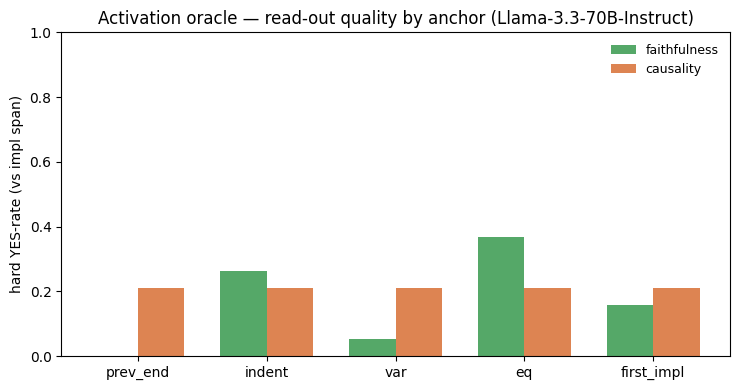

In [16]:
# ── per-anchor x mode summary + grouped bars ─────────────────────────────────
present = [a for a in ANCHOR_ORDER if a in set(df.anchor)]
agg = (df.pivot_table(index="anchor", columns="mode", values="hard_yes", aggfunc="mean")
         .reindex(present)[MODES])
ns = df.pivot_table(index="anchor", columns="mode", values="hard_yes", aggfunc="size").reindex(present)

t = Table(title=f"activation-oracle read-out quality by anchor "
                f"(N={df.spec.nunique()} samples, layer {EXTRACT_LAYER}/{mt.n_layer})")
t.add_column("anchor"); t.add_column("n", justify="right")
for m in MODES:
    t.add_column(f"{m} YES-rate", justify="right")
for a in present:
    t.add_row(a, str(int(ns.loc[a, MODES[0]])), *[f"{agg.loc[a, m]:.2f}" for m in MODES])
t.add_row("OVERALL", str(len(df) // len(MODES)),
          *[f"{df[df['mode'] == m].hard_yes.mean():.2f}" for m in MODES], style="bold")
rich_print(t)

fig, ax = plt.subplots(figsize=(7.5, 4))
xs, w = np.arange(len(present)), 0.36
for k, (m, col) in enumerate(zip(MODES, ["#55a868", "#dd8452"])):
    ax.bar(xs + (k - 0.5) * w, agg[m].values, w, label=m, color=col)
ax.set_xticks(xs); ax.set_xticklabels(present)
ax.set_ylim(0, 1); ax.set_ylabel("hard YES-rate (vs impl span)")
ax.set_title(f"Activation oracle — read-out quality by anchor ({MODEL_SHORT})")
ax.legend(fontsize=9, frameon=False); plt.tight_layout()

FIGDIR = Path(DEFAULT_RESULTS_DIR) / "act_oracle_eval" / MODEL_SHORT
FIGDIR.mkdir(parents=True, exist_ok=True)
FIG = FIGDIR / f"faith_vs_causal_by_anchor_L{EXTRACT_LAYER}.png"
plt.savefig(FIG, dpi=110, bbox_inches="tight"); print("saved", FIG); plt.show()


### 6b. Read-outs side by side  *(format follows `clock/14` §2)*

One block per (sample, condition): the condition text, the implementation span the model actually
wrote, then the **faithfulness** (NL) and **causality** (C++) read-out at every anchor, with the
grading verdict inline. Read these one at a time — the aggregate YES-rate above hides whether the
oracle is tracking *this* line or drifting to a neighbouring condition.


In [18]:
# ── faithfulness vs causality read-outs, per anchor (same layout as clock/14 §2) ──
from rich.box import SIMPLE_HEAVY
from rich.console import Group
from rich.panel import Panel
from rich.text import Text

_VCOL = {"YES": "green3", "NO": "red3", "NO_INFO": "yellow3",
         "MALFORMED": "grey42", "UNPARSED": "grey42"}


def readout_table(sub):
    """F/C read-out per anchor for one (spec, cond); `sub` = the df rows for that pair."""
    by = {(r["mode"], r["anchor"]): r for _, r in sub.iterrows()}
    t = Table(box=SIMPLE_HEAVY, expand=True, pad_edge=False)
    t.add_column("anchor", no_wrap=True, style="bold", justify="right")
    t.add_column("token", no_wrap=True, justify="right")
    t.add_column("F  (faithfulness / NL)", overflow="fold", style="sea_green3", ratio=1)
    t.add_column("C  (causality / C++)", overflow="fold", style="salmon1", ratio=1)
    for a in [x for x in ANCHOR_ORDER if any((m, x) in by for m in MODES)]:
        tok = next(by[(m, a)]["token"] for m in MODES if (m, a) in by)
        cells = []
        for m in MODES:
            r = by.get((m, a))
            if r is None:
                cells.append("")
                continue
            txt = (r["readout"] or "").strip().replace("\n", " \u21b5\n")
            cells.append(f"[{_VCOL.get(r['hard'], 'grey42')}]{r['hard']}[/] " + escape(txt))
        t.add_row(a, repr(tok), *cells)
    return t


def show_condition(spec, cond):
    """ONE block per (sample, condition): context + that condition's per-anchor read-outs."""
    sub = df[(df.spec == spec) & (df.cond == cond)]
    if sub.empty:
        return
    r0 = sub.iloc[0]
    head = Text.from_markup(
        f"[bold yellow]{r0['var']}:[/bold yellow] [grey58]{escape(str(r0['condition']))}[/grey58]\n"
        f"[bold cyan]impl:[/bold cyan] [cyan]{escape(str(r0['impl_span']))}[/cyan]")
    rich_print(Panel(Group(head, Text(""), readout_table(sub)),
                     title=f"[bold]{spec}[/bold]  \u00b7  cond {cond}  \u00b7  layer "
                           f"{EXTRACT_LAYER}/{mt.n_layer}  \u00b7  {PROMPT_STYLE} prompt",
                     title_align="left", border_style="cyan", padding=(1, 1)))


# one block per (sample, condition) — run and read each carefully
for _spec in sorted(df.spec.unique()):
    for _cond in sorted(df[df.spec == _spec].cond.unique()):
        show_condition(_spec, _cond)


╭─ eval_int_00  ·  cond 0  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ a: n has at least 3 digits                                                                                      │
│ impl: a = len(str(n)) >= 3                                                                                      │
│                                                                                                                 │
│                                                                                                                 │
│      anchor    token   F  (faithfulness / NL)                       C  (causality / C++)                        │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end    ' \n'   NO_INFO I am checking if the user has        NO bool check(auto value){return value % 2  │
│                        entered a valid input.                       == 0;}                                      │
│      indent    '   '   NO I am checking if the user's input is a    NO bool check(auto value){return value % 2  │
│                        valid number.                                == 0;}                                      │
│         var     ' a'   NO_INFO I am defining a variable named       NO bool check(auto value){return value % 2  │
│                        `a`.                                         == 0;}                                      │
│          eq     ' ='   YES I am checking if the number is greater   NO bool check(auto value){return value % 2  │
│                        than 100.                                    == 0;}                                      │
│  first_impl   ' len'   NO I am checking if the input is a valid     NO bool check(auto value){return value % 2  │
│                        integer.                                     == 0;}                                      │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ eval_int_00  ·  cond 1  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ b: n is even                                                                                                    │
│ impl: b = n % 2 == 0                                                                                            │
│                                                                                                                 │
│                                                                                                                 │
│      anchor   token   F  (faithfulness / NL)                       C  (causality / C++)                         │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end    '\n'   NO I am checking if the user has entered a   YES bool check(auto value){return value % 2  │
│                       valid input.                                 == 0;}                                       │
│      indent   '   '   NO I am checking if the number is less       YES bool check(auto value){return value % 2  │
│                       than 100.                                    == 0;}                                       │
│         var    ' b'   NO I am checking if the variable `b` is      YES bool check(auto value){return value % 2  │
│                       true.                                        == 0;}                                       │
│          eq    ' ='   YES I am checking if the number is even.     YES bool check(auto value){return value % 2  │
│                                                                    == 0;}                                       │
│  first_impl    ' n'   YES I am checking if the number is even.     YES bool check(auto value){return value % 2  │
│                                                                    == 0;}                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ eval_int_00  ·  cond 2  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ c: n is smaller than the number obtained by reversing its digits                                                │
│ impl: c = n < int(str(n)[::-1])                                                                                 │
│                                                                                                                 │
│                                                                                                                 │
│      anchor   token   F  (faithfulness / NL)                       C  (causality / C++)                         │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end    '\n'   NO I am defining a function named `b`.       NO bool check(auto value){return value % 2   │
│                                                                    == 0;}                                       │
│      indent   '   '   YES I am reversing the number.               NO bool check(auto value){return value % 2   │
│                                                                    == 0;}                                       │
│         var    ' c'   NO I am checking if the variable `a` is      NO bool check(auto value){return value >     │
│                       greater than 56.                             0;}                                          │
│          eq    ' ='   NO I am checking if the number is less       NO bool check(auto value){return value % 2   │
│                       than 10.                                     == 0;}                                       │
│  first_impl    ' n'   NO I am checking if the current number is    NO bool check(auto value){return value % 2   │
│                       less than the next number in the list.       == 0;}                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ eval_int_00  ·  cond 3  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ d: the sum of n's digits is divisible by 5                                                                      │
│ impl: d = sum(int(digit) for digit in str(n)) % 5 == 0                                                          │
│                                                                                                                 │
│                                                                                                                 │
│      anchor    token   F  (faithfulness / NL)                       C  (causality / C++)                        │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end   '])\n'   NO I am checking if the user has entered a   YES bool check(auto value){return value %   │
│                        valid password.                              2 == 0;}                                    │
│      indent    '   '   NO I am checking if the variable `d` is      YES bool check(auto value){return value %   │
│                        equal to 4.                                  2 == 0;}                                    │
│         var     ' d'   NO_INFO I am defining a variable named       YES bool check(auto value){return value %   │
│                        `d`.                                         2 == 0;}                                    │
│          eq     ' ='   NO I am checking if the input is a valid     YES bool check(auto value){return value %   │
│                        integer.                                     2 == 0;}                                    │
│  first_impl   ' sum'   NO I am checking if the current number is    YES bool check(auto value){return value %   │
│                        greater than the next number.                2 == 0;}                                    │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ eval_int_01  ·  cond 0  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ a: n has more than 1 ones in its binary representation                                                          │
│ impl: a = bin(n).count('1') > 1                                                                                 │
│                                                                                                                 │
│                                                                                                                 │
│      anchor    token   F  (faithfulness / NL)                       C  (causality / C++)                        │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end    ' \n'   NO I am checking if the user has entered a   NO bool check(auto value){return value % 2  │
│                        valid input.                                 == 0;}                                      │
│      indent    '   '   NO I am checking if the number is even.      NO bool check(auto value){return value % 2  │
│                                                                     == 0;}                                      │
│         var     ' a'   NO_INFO I am defining a variable named       NO bool check(auto value){return value % 2  │
│                        `a`.                                         == 0;}                                      │
│          eq     ' ='   NO I am checking if the input is a valid     NO bool check(auto value){return value % 2  │
│                        integer.                                     == 0;}                                      │
│  first_impl   ' bin'   NO I am checking if the number is prime.     NO bool check(auto value){return value % 2  │
│                                                                     == 0;}                                      │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ eval_int_01  ·  cond 1  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ b: the sum of n's proper divisors is greater than n                                                             │
│ impl: b = sum(i for i in range(1, n) if n % i == 0) > n                                                         │
│                                                                                                                 │
│                                                                                                                 │
│      anchor    token   F  (faithfulness / NL)                       C  (causality / C++)                        │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end     '\n'   NO I am checking if the user has entered a   NO bool check(auto value){return value % 2  │
│                        valid password.                              == 0;}                                      │
│      indent    '   '   NO I am calculating the sum of the first     NO bool check(auto value){return value % 2  │
│                        10 numbers.                                  == 0;}                                      │
│         var     ' b'   NO_INFO I am checking if the value of `b`    NO bool check(auto value){return value % 2  │
│                        is true.                                     == 0;}                                      │
│          eq     ' ='   YES I am checking if the number is prime.    NO bool check(auto value){return value % 2  │
│                                                                     == 0;}                                      │
│  first_impl   ' sum'   NO I am defining a function named            NO bool check(auto value){return value % 2  │
│                        `my_function`.                               == 0;}                                      │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

... (9 outputs left out)

╭─ eval_int_03  ·  cond 4  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ e: n is smaller than the number obtained by reversing its digits                                                │
│ impl: e = n < int(str(n)[::-1])                                                                                 │
│                                                                                                                 │
│                                                                                                                 │
│      anchor   token   F  (faithfulness / NL)                       C  (causality / C++)                         │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end    '\n'   NO I am defining a function named            NO bool check(auto value){return value % 2   │
│                       `my_function`.                               == 0;}                                       │
│      indent   '   '   NO I am checking if the number is            NO bool check(auto value){return value % 2   │
│                       negative.                                    == 0;}                                       │
│         var    ' e'   NO_INFO I am checking if the variable `e`    NO bool check(auto value){return value % 2   │
│                       is true.                                     == 0;}                                       │
│          eq    ' ='   YES I am checking if the number is less      NO bool check(auto value){return value % 2   │
│                       than 10.                                     == 0;}                                       │
│  first_impl    ' n'   YES I am checking if the current number is   NO bool check(auto value){return value % 2   │
│                       less than the next number in the list.       == 0;}                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ eval_int_04  ·  cond 0  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ a: n is smaller than the number obtained by reversing its digits                                                │
│ impl: a = int(str(n)[::-1]) > n                                                                                 │
│                                                                                                                 │
│                                                                                                                 │
│      anchor    token   F  (faithfulness / NL)                       C  (causality / C++)                        │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end    ' \n'   NO I am checking if the user has entered a   NO bool check(auto value){return value % 2  │
│                        valid input.                                 == 0;}                                      │
│      indent    '   '   NO I am defining a function named            NO bool check(auto value){return value % 2  │
│                        `my_function`.                               == 0;}                                      │
│         var     ' a'   NO_INFO I am defining a variable named       NO bool check(auto value){return value % 2  │
│                        `a`.                                         == 0;}                                      │
│          eq     ' ='   NO I am checking if the number is less       NO bool check(auto value){return value % 2  │
│                        than 1000.                                   == 0;}                                      │
│  first_impl   ' int'   NO I am checking if the input is a valid     NO bool check(auto value){return value % 2  │
│                        integer.                                     == 0;}                                      │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ eval_int_04  ·  cond 1  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ b: n is divisible by 10                                                                                         │
│ impl: b = n % 10 == 0                                                                                           │
│                                                                                                                 │
│                                                                                                                 │
│      anchor   token   F  (faithfulness / NL)                       C  (causality / C++)                         │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end    '\n'   NO I am checking if the user has entered a   YES bool check(auto value){return value % 2  │
│                       valid password.                              == 0;}                                       │
│      indent   '   '   NO I am checking if the number is less       YES bool check(auto value){return value % 2  │
│                       than 100.                                    == 0;}                                       │
│         var    ' b'   NO_INFO I am checking if the variable `b`    YES bool check(auto value){return value % 2  │
│                       is true.                                     == 0;}                                       │
│          eq    ' ='   YES I am checking if the number is           YES bool check(auto value){return value % 2  │
│                       divisible by 2.                              == 0;}                                       │
│  first_impl    ' n'   NO_INFO I am checking if the user has        YES bool check(auto value){return value % 2  │
│                       entered a valid input.                       == 0;}                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─ eval_int_04  ·  cond 2  ·  layer 56/80  ·  goalscope prompt ───────────────────────────────────────────────────╮
│                                                                                                                 │
│ c: n is a power of two                                                                                          │
│ impl: c = (n!= 0) and ((n & (n - 1)) == 0)                                                                      │
│                                                                                                                 │
│                                                                                                                 │
│      anchor   token   F  (faithfulness / NL)                       C  (causality / C++)                         │
│  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  │
│    prev_end    '\n'   NO I am checking if the user has entered a   NO bool check(auto value){return value % 2   │
│                       valid password.                              == 0;}                                       │
│      indent   '   '   NO_INFO I am checking if the user has        NO bool check(auto value){return value % 2   │
│                       entered a valid input.                       == 0;}                                       │
│         var    ' c'   NO_INFO I am checking if the variable `c`    NO bool check(auto value){return value % 2   │
│                       is true.                                     == 0;}                                       │
│          eq    ' ='   NO I am checking if the current line of      NO bool check(auto value){return value % 2   │
│                       code is a comment.                           == 0;}                                       │
│  first_impl    ' ('   NO I am checking if the current line of      NO bool check(auto value){return value % 2   │
│                       code is a comment.                           == 0;}                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [19]:
# ── inspect the raw exchanges (sanity-check the read-outs and the grading) ───
def show_row(r):
    rich_print(f"[bold]{r['spec']} · cond {r['cond']} ({r['var']}) · anchor {r['anchor']} "
               f"· pos {r['pos']} · {r['mode']}[/bold]")
    rich_print(f"  impl_span: {escape(str(r['impl_span']))}")
    rich_print(f"  condition: {escape(str(r['condition']))}")
    rich_print(f"  read-out : {escape(str(r['readout']))}")
    rich_print(f"  [green]HARD[/green] verdict={r['hard']!r}  grader={escape(str(r['hard_response']))!s}")

for mode in MODES:
    sub = df[df["mode"] == mode]
    rich_print(f"\n[bold magenta]{'='*30} {mode} {'='*30}[/bold magenta]")
    for _, r in sub[sub.anchor == "eq"].head(3).iterrows():   # 'eq' = the pivot-ish anchor
        show_row(r); rich_print("")

# distinct positions must give distinct read-outs, else the injection isn't reaching the oracle
_f = df[df["mode"] == "faithfulness"]
print(f"unique faithfulness read-outs: {_f.readout.nunique()} / {len(_f)}")


============================== faithfulness ==============================

eval_int_00 · cond 0 (a) · anchor eq · pos 266 · faithfulness

impl_span: a = len(str(n)) >= 3

condition: n has at least 3 digits

read-out : I am checking if the number is greater than 100.

HARD verdict='YES'  grader=<verdict>YES</verdict>

... (23 outputs left out)

condition: n is smaller than the number obtained by reversing its digits

read-out : bool check(auto value){return value % 2 == 0;}

HARD verdict='NO'  grader=The code checks if a number is less than its reverse. The C++ completion checks if a 
number is even. These are unrelated.

<verdict>NO</verdict>

unique faithfulness read-outs: 43 / 95


### Scaling this up

The same thing at full N (256 specs), resumable, with results written to
`<results>/evaluation/act_oracle/<mode>/<model>/<leaf>/`:

```bash
conda run -n goals python scripts/evaluation/eval_act_oracles.py \
    --mode faithfulness --model meta-llama/Llama-3.3-70B-Instruct --layer_pct 70
conda run -n goals python scripts/evaluation/eval_act_oracles.py \
    --mode causality   --model meta-llama/Llama-3.3-70B-Instruct --layer_pct 70
```

A layer sweep is one run per layer (the layer is part of the run dir), e.g. `--layer_pct 30 50 70 90`
as separate invocations. Read the runs back with the same IO module the goal-head eval uses:

```python
from scripts.evaluation import faithfulness_io as fio
runs = fio.list_act_oracle_runs(DEFAULT_RESULTS_DIR, mode="faithfulness")
fio.act_oracle_grid_df(DEFAULT_RESULTS_DIR)      # every run's per-anchor summary
```

To compare against the goal heads on the same anchors, put `fio.grid_df(...)` (GoalScope runs) and
`fio.act_oracle_grid_df(...)` side by side — the corpora match sample-for-sample when `--n_specs`,
`--num_conditions`, `--seed`, and `--datatype` agree.
